# LSTM price prediction

**Goal.** See whether an LSTM on past prices beats "tomorrow equals today," with the scaler fit on the training window only.

**Method.** NVDA daily closes from 2018. Time split, first 80% / last 20%. `MinMaxScaler` is fit on training prices and then applied to the whole series. Inputs are 60-day windows. Two LSTM layers of 50 units, dropout 0.2, 20 epochs. The naive forecast is the previous close.

**Result.** LSTM error $8.18 per day. Naive baseline $3.57 per day. Validation loss in the log below is several times the training loss, and at times about 10 to 20 times larger. Fitting the scaler on training data only also caps what the model can output near the top of the training price range. The returns test is in the next notebook.


[*********************100%***********************]  1 of 1 completed

Epoch 1/20


49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0047 - val_loss: 0.0220
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 7.4164e-04 - val_loss: 0.0072
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 5.7360e-04 - val_loss: 0.0048
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 4.6997e-04 - val_loss: 0.0031
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 4.6936e-04 - val_loss: 0.0029
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 4.9776e-04 - val_loss: 0.0029
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 5.3240e-04 - val_loss: 0.0033
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 5.2255e-04 - val_loss: 0.0126
Epoch 9/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 5.2605e-04 - val_loss: 0.0038
Epoch 10/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 3.8345e-04 - val_loss: 0.0027
Epoch 11/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 4.0060e-04 - val_loss: 0.0040
Epoch 12/20
49/49 ━━━━━━━━━━━━━━━━

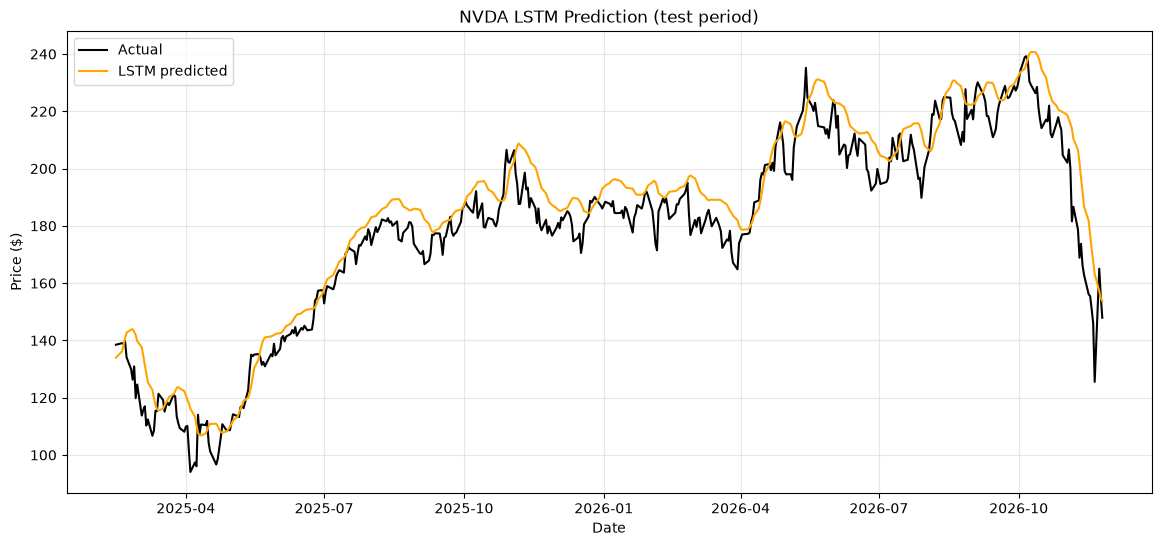

In [1]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

ticker = "NVDA"
window = 60   # use the last 60 days to predict the next day

# Download data
df = yf.download(ticker, start="2018-01-01", multi_level_index=False)[["Close"]].dropna()
prices = df["Close"].values.reshape(-1, 1)

# Train/test split by time (first 80% train, last 20% test)
split = int(len(prices) * 0.8)

# Scale with MinMaxScaler, fit on TRAINING data only (no peeking at the future)
scaler = MinMaxScaler()
scaler.fit(prices[:split])
scaled = scaler.transform(prices)

# Build 60-day windows: X = 60 past days, y = the next day
def make_windows(data, start, end):
    X, y = [], []
    for i in range(start, end):
        X.append(data[i - window:i, 0])
        y.append(data[i, 0])
    return np.array(X).reshape(-1, window, 1), np.array(y)

X_train, y_train = make_windows(scaled, window, split)
X_test, y_test = make_windows(scaled, split, len(scaled))

# Build the LSTM model
model = Sequential([
    Input(shape=(window, 1)),
    LSTM(50, return_sequences=True),
    Dropout(0.2),
    LSTM(50),
    Dropout(0.2),
    Dense(1),
])
model.compile(optimizer="adam", loss="mse")

# Train
model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.1, verbose=1)

# Test: predict, then convert back to dollars
pred = scaler.inverse_transform(model.predict(X_test))
actual = prices[split:]
naive = prices[split - 1:-1]   # "tomorrow = today"

print(f"\nLSTM error:     ${mean_absolute_error(actual, pred):.2f} per day")
print(f"Naive baseline: ${mean_absolute_error(actual, naive):.2f} per day")

# Plot
test_dates = df.index[split:]
plt.figure(figsize=(14, 6))
plt.plot(test_dates, actual, label="Actual", color="black")
plt.plot(test_dates, pred, label="LSTM predicted", color="orange")
plt.title(f"{ticker} LSTM Prediction (test period)")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
